## DSAN 6000 Week 5 Demo: From Pandas to Polars

## (1) Polars: Writing *and* Optimally-Executing "Pieces" of Computation in Python

During class last week (and on HW4) we started translating Pandas **code** into DuckDB SQL **queries**, as part of our broader endeavor in this class to start [**decoupling data from computation!**](https://motherduck.com/blog/separating-storage-compute-duckdb/)

Now that you've experienced what it's like to **explicitly** separate code from data in DuckDB — where you wrote the *computation* in an SQL string, then *executed it* on a *particular dataset* using Python's `duckdb` library — this week (and on HW5) we are using **Polars** to achieve both goals within the *same* language:

* (a) Using **Python** code to construct "pieces" of computation (called **expressions**), ***and***
* (b) Using **Python** code again to apply these pieces to particular datasets.



## (2) Immediate But *Non-Optimized* Results with Pandas

To refresh what we learned last week: In an **eager-evaluation** setting like Pandas code, when we write a data-processing pipeline, the steps are **immediately evaluated**, line-by-line (like any other Python code). Consider the following example, where the goal of the pipeline is to figure out our average ratio of sleep hours to work hours on weekdays:

In [ ]:
#| label: sleep-df-create
import pandas as pd
import numpy as np
rng = np.random.default_rng(seed=6000)
import calendar
list(calendar.day_name)
sleep_df = pd.DataFrame({
  'day': list(calendar.day_name),
  'sleep_hrs': rng.uniform(3, 8, size=7),
  'work_hrs': rng.uniform(6, 10, size=7),
})
display(sleep_df)
sleep_df.to_csv("sleep.csv", index=False)

,day,sleep_hrs,work_hrs
0,Monday,6.089095,7.418997
1,Tuesday,7.912447,8.747633
2,Wednesday,5.393727,6.011502
3,Thursday,4.347202,7.318025
4,Friday,4.556042,6.341836
5,Saturday,4.552443,7.279092
6,Sunday,6.606959,6.652768


In [ ]:
#| label: sleep-compute-ratios
# Step 1: Compute ratios
ratio_df = sleep_df.copy()
ratio_df['ratio'] = ratio_df['work_hrs'] / ratio_df['sleep_hrs']
display(ratio_df)

,day,sleep_hrs,work_hrs,ratio
0,Monday,6.089095,7.418997,1.218407
1,Tuesday,7.912447,8.747633,1.105553
2,Wednesday,5.393727,6.011502,1.114536
3,Thursday,4.347202,7.318025,1.683387
4,Friday,4.556042,6.341836,1.391962
5,Saturday,4.552443,7.279092,1.598942
6,Sunday,6.606959,6.652768,1.006934


In [ ]:
#| label: sleep-filter-weekends
# Step 2: Filter to just weekdays
weekend_days = ['Saturday', 'Sunday']
weekday_df = ratio_df[~ratio_df['day'].isin(weekend_days)]
display(weekday_df)

,day,sleep_hrs,work_hrs,ratio
0,Monday,6.089095,7.418997,1.218407
1,Tuesday,7.912447,8.747633,1.105553
2,Wednesday,5.393727,6.011502,1.114536
3,Thursday,4.347202,7.318025,1.683387
4,Friday,4.556042,6.341836,1.391962


In [ ]:
#| label: sleep-compute-mean
# Step 3: Compute mean ratio over the weekdays
weekday_df['ratio'].mean()

np.float64(1.3027691063719424)

Notice here, however, that we are carrying out **unnecessary computations** in Step 1! Since we're going to **drop** the weekend rows in Step 2 anyways, there is no need to compute the ratio for these two days. Since Python (and thus Pandas) is evaluated line-by-line, however, Pandas has no way of knowing that these two ratios don't need to be computed. It simply does what it is told, dutifully computing all 7 ratios.

## (3) Deferred But *Optimized* Results with Polars

With Polars in our toolbox, we unlock an **alternative approach** to the above: we can **write out our "plan"** for this pipeline **in advance**, in the form of a **query**, **before** actually running any code!

Polars can then **scan over our query** and figure out that we don't need to compute ratios for weekend days, since they would be dropped in Step 2! Here is the same pipeline re-written using Polars' `LazyFrame` in place of a Pandas `DataFrame`:

In [ ]:
!wget https://raw.githubusercontent.com/jpowerj/dsan-content/refs/heads/main/2026-fall-dsan6000/sleep.csv

--2026-09-28 08:26:59--  https://raw.githubusercontent.com/jpowerj/dsan-content/refs/heads/main/2026-fall-dsan6000/sleep.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 332 [text/plain]
Saving to: ‘sleep.csv’

sleep.csv           100%[===================>]     332  --.-KB/s    in 0s      

2026-09-28 08:26:59 (14.7 MB/s) - ‘sleep.csv’ saved [332/332]



In [ ]:
#| label: sleep-polars
import polars as pl
weekend_days = ['Saturday', 'Sunday']
sleep_pl = pl.scan_csv('sleep.csv')
compute_ratio_expr = pl.col('work_hrs') / pl.col('sleep_hrs')
compute_ratios_expr = (
  sleep_pl.with_columns(
    compute_ratio_expr.alias('ratio')
  ).filter(~pl.col('day').is_in(weekend_days))
)

Note that **no computation has actually taken place yet!** We have just **written out our *plan*** for the computation, in the form of Polars expressions (which don't actually run until they're paired with a **context**).

Because of this, we can see Polars' query optimization engine in action. First, we can use the `optimized=False` argument to `show_graph()` to see what our pipeline looks like **without** any optimizations (that is, running line-by-line as written, as our Pandas code did above):

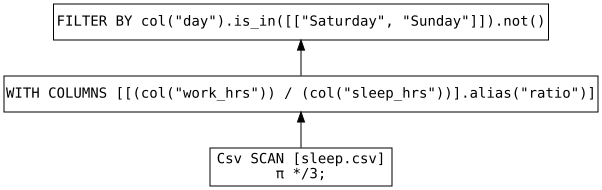

In [ ]:
#| label: sleep-polars-non-optimized
compute_ratios_expr.show_graph(optimized=False)

Remember that these query plans should be read from **bottom to top**. Now, compare that with the following graph, which shows our query **after** Polars scans over our instructions, detecting points where it can re-arrange our pipeline for greater efficiency:

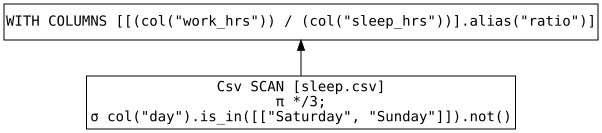

In [ ]:
#| label: sleep-polars-optimized
compute_ratios_expr.show_graph()

Notice the difference in the ordering of steps: Polars has successfully figured out that it should **filter out the weekend days *before* carrying out the calculations!** In fact, in this example, it figures out that it doesn't even need to **read** these columns in from the file on disk.

## (4) Constructing Expressions in Polars

Now, let's slow down and look at how exactly we "translated" the original Pandas workflow into the lazily-evaluated Polars expression in the previous section. You can read a full-on classification and overview of each expression in the Janssens and Nieuwdorp book ([*Python Polars: The Definitive Guide* (2025)](https://www.dropbox.com/scl/fi/l1lz7dqz1nhumbvmre408/PythonPolars_TheDefinitiveGuide.pdf?rlkey=6nbdad5khui8tc2qe1i8yhv4c&dl=1))

In [ ]:
import polars as pl
pima_lf = pl.scan_parquet(
    "s3://dsan6000-data/pima-deaths/**/*.parquet",
    hive_partitioning=True,
    storage_options={
        "aws_region": "us-east-1",
        "aws_skip_signature": "true",
    },
)

In [ ]:
pima_lf.collect_schema()

Schema([('ML Number', String),
        ('Name', String),
        ('Sex', String),
        ('Age', Float64),
        ('Reporting Date', String),
        ('Surface Management', String),
        ('Location', String),
        ('Location Precision', String),
        ('Corridor Code', Int64),
        ('Corridor', String),
        ('Cause of Death', String),
        ('OME Determined COD', String),
        ('Condition Code', Float64),
        ('Body Condition', String),
        ('Post Mortem Interval', String),
        ('State', String),
        ('County', String),
        ('Latitude', Float64),
        ('Longitude', Float64),
        ('UTM X', Int64),
        ('UTM Y', Int64),
        ('date_parsed', Datetime(time_unit='us', time_zone=None)),
        ('year', Int64)])

In [ ]:
pima_lf.head(5).collect()

ML Number,Name,Sex,Age,Reporting Date,Surface Management,Location,Location Precision,Corridor Code,Corridor,Cause of Death,OME Determined COD,Condition Code,Body Condition,Post Mortem Interval,State,County,Latitude,Longitude,UTM X,UTM Y,date_parsed,year
str,str,str,f64,str,str,str,str,i64,str,str,str,f64,str,str,str,str,f64,f64,i64,i64,datetime[μs],i64
"""02-00046""","""ARGUELLAS-HERRERA, CESAR LEOBA…","""male""",30.0,"""2002-01-06""","""Tohono Oodham Nation""","""HWY 86 MP 64/FED RT 34""","""vague physical description (pr…",8,"""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",32.206227,-112.571943,351848,3564378,2002-01-06 00:00:00,2002
"""02-00064""","""LOZANO-DE LA ROSA, MARIA LUISA…","""female""",32.0,"""2002-01-08""","""State of Arizona""","""36 500 SOUTH 17 300 WEST""","""GPS Coordinate (precise to wit…",6,"""Sasabe""","""Undetermined""","""UNDETERMINED""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",31.60833,-111.28833,472652,3497059,2002-01-08 00:00:00,2002
"""02-00166""","""MOLINA PEREZ, TOMAS""","""male""",35.0,"""2002-01-27""","""Pima County Office of the Medi…","""SMH MORGUE""","""individual moved from location…",13,"""North of Corridor Divisions""","""Exposure""","""MULTISYSTEM ORGAN FAILURE COMP…",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Unknown""",32.175119,-110.928097,506780,3559848,2002-01-27 00:00:00,2002
"""02-00285""","""MARTINEZ-GRIJALVA, MARTIN""","""male""",38.0,"""2002-02-18""","""Bureau of Land Management""",null,"""physical description with dire…",7,"""San Miguel""","""Skeletal Remains""","""UNDETERMINED DUE TO SKELETAL R…",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",32.40864,-111.5523,448066,3585865,2002-02-18 00:00:00,2002
"""02-00291""","""GRACIA-AGUIRRE, CARLOS""","""male""",25.0,"""2002-02-19""","""Tohono Oodham Nation""","""SR 86, MP 74""","""physical description with dire…",8,"""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",32.189906,-112.40556,367507,3562351,2002-02-19 00:00:00,2002


### (4.1) `select()` for Subsetting Columns

In [ ]:
string_cols_expr = pl.col(pl.String)
print(type(string_cols_expr))
string_col_lf = pima_lf.select(string_cols_expr)
print(type(string_col_lf))
string_col_lf

<class 'polars.expr.expr.Expr'>
<class 'polars.lazyframe.frame.LazyFrame'>


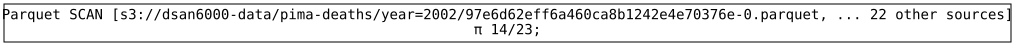

In [ ]:
string_col_lf.show_graph()

In [ ]:
result_pl = string_col_lf.collect()
print(type(result_pl))
result_pl

<class 'polars.dataframe.frame.DataFrame'>


ML Number,Name,Sex,Reporting Date,Surface Management,Location,Location Precision,Corridor,Cause of Death,OME Determined COD,Body Condition,Post Mortem Interval,State,County
str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""02-00046""","""ARGUELLAS-HERRERA, CESAR LEOBA…","""male""","""2002-01-06""","""Tohono Oodham Nation""","""HWY 86 MP 64/FED RT 34""","""vague physical description (pr…","""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""","""Fully fleshed""","""< 1 day""","""Arizona""","""Pima"""
"""02-00064""","""LOZANO-DE LA ROSA, MARIA LUISA…","""female""","""2002-01-08""","""State of Arizona""","""36 500 SOUTH 17 300 WEST""","""GPS Coordinate (precise to wit…","""Sasabe""","""Undetermined""","""UNDETERMINED""","""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima"""
"""02-00166""","""MOLINA PEREZ, TOMAS""","""male""","""2002-01-27""","""Pima County Office of the Medi…","""SMH MORGUE""","""individual moved from location…","""North of Corridor Divisions""","""Exposure""","""MULTISYSTEM ORGAN FAILURE COMP…","""Fully fleshed""","""< 1 day""","""Arizona""","""Unknown"""
"""02-00285""","""MARTINEZ-GRIJALVA, MARTIN""","""male""","""2002-02-18""","""Bureau of Land Management""",null,"""physical description with dire…","""San Miguel""","""Skeletal Remains""","""UNDETERMINED DUE TO SKELETAL R…","""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima"""
"""02-00291""","""GRACIA-AGUIRRE, CARLOS""","""male""","""2002-02-19""","""Tohono Oodham Nation""","""SR 86, MP 74""","""physical description with dire…","""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""","""Fully fleshed""","""< 1 day""","""Arizona""","""Pima"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""24-4454""","""Unidentified""","""male""","""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…","""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""","""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA"""
"""24-4455""","""Unidentified""","""female""","""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…","""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""","""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA"""
"""24-4456""","""Unidentified""","""male""","""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…","""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""","""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA"""


### (4.2) `filter()` for Subsetting Rows

In [ ]:
recent_year_expr = pl.col("year") >= 2020
print(type(recent_year_expr))
recent_lf = pima_lf.filter(recent_year_expr)
print(type(recent_lf))
recent_lf

<class 'polars.expr.expr.Expr'>
<class 'polars.lazyframe.frame.LazyFrame'>


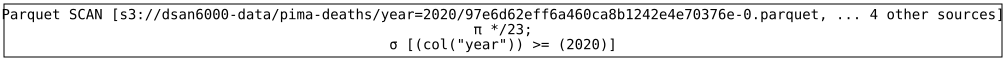

In [ ]:
recent_lf.show_graph()

In [ ]:
result_pl = recent_lf.collect()
print(type(result_pl))
result_pl

<class 'polars.dataframe.frame.DataFrame'>


ML Number,Name,Sex,Age,Reporting Date,Surface Management,Location,Location Precision,Corridor Code,Corridor,Cause of Death,OME Determined COD,Condition Code,Body Condition,Post Mortem Interval,State,County,Latitude,Longitude,UTM X,UTM Y,date_parsed,year
str,str,str,f64,str,str,str,str,i64,str,str,str,f64,str,str,str,str,f64,f64,i64,i64,datetime[μs],i64
"""20-0025""","""Unidentified""","""male""",null,"""2020-01-02""","""Tohono Oodham Nation""",null,"""GPS Coordinate (precise to wit…",8,"""Cowlick""","""Skeletal Remains""","""UNDETERMINED (SKELETAL REMAINS…",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",32.35061,-112.33691,374201,3580084,2020-01-02 00:00:00,2020
"""20-0036""","""Unidentified""","""male""",null,"""2020-01-03""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",32.44845,-113.11031,301628,3592105,2020-01-03 00:00:00,2020
"""20-0046""","""Unidentified""","""male""",null,"""2020-01-04""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Undetermined""","""Undetermined""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",32.4147,-113.255983,287853,3588643,2020-01-04 00:00:00,2020
"""20-0065""","""Unidentified""","""female""",null,"""2020-01-05""","""State of Arizona""",null,"""GPS Coordinate (precise to wit…",4,"""Patagonia""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",31.969466,-110.4881,548369,3537165,2020-01-05 00:00:00,2020
"""20-0083""","""Garcia Lopez, Adrian""","""male""",41.0,"""2020-01-07""","""Tohono Oodham Nation""",null,"""GPS Coordinate (precise to wit…",7,"""San Miguel""","""Exposure""","""Hypothermia""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",31.751483,-111.60035,443142,3513046,2020-01-07 00:00:00,2020
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""24-4454""","""Unidentified""","""male""",null,"""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA""",32.2653,-113.10238,301975,3571782,2024-12-25 00:00:00,2024
"""24-4455""","""Unidentified""","""female""",null,"""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA""",32.26766,-113.10685,301559,3572052,2024-12-25 00:00:00,2024
"""24-4456""","""Unidentified""","""male""",null,"""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA""",32.26017,-113.08439,303658,3571180,2024-12-25 00:00:00,2024


## (5) *Reusing* Expressions: The Importance of `alias()`

In [ ]:
is_male_expr = (pl.col('Sex') == 'male').alias('is_male')
print(type(is_male_expr))

<class 'polars.expr.expr.Expr'>


### (5.1) Use Expression to Generate a New Column

<class 'polars.lazyframe.frame.LazyFrame'>


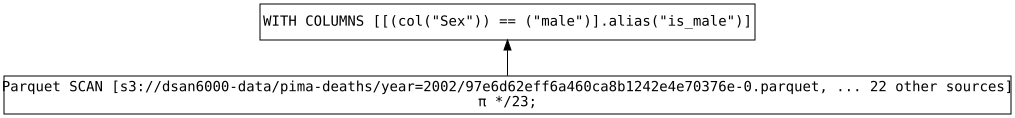

In [ ]:
new_col_lf = pima_lf.with_columns(is_male_expr)
print(type(new_col_lf))
new_col_lf.show_graph()

In [ ]:
new_col_pl = new_col_lf.collect()
print(type(new_col_pl))
new_col_pl

<class 'polars.dataframe.frame.DataFrame'>


ML Number,Name,Sex,Age,Reporting Date,Surface Management,Location,Location Precision,Corridor Code,Corridor,Cause of Death,OME Determined COD,Condition Code,Body Condition,Post Mortem Interval,State,County,Latitude,Longitude,UTM X,UTM Y,date_parsed,year,is_male
str,str,str,f64,str,str,str,str,i64,str,str,str,f64,str,str,str,str,f64,f64,i64,i64,datetime[μs],i64,bool
"""02-00046""","""ARGUELLAS-HERRERA, CESAR LEOBA…","""male""",30.0,"""2002-01-06""","""Tohono Oodham Nation""","""HWY 86 MP 64/FED RT 34""","""vague physical description (pr…",8,"""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",32.206227,-112.571943,351848,3564378,2002-01-06 00:00:00,2002,true
"""02-00064""","""LOZANO-DE LA ROSA, MARIA LUISA…","""female""",32.0,"""2002-01-08""","""State of Arizona""","""36 500 SOUTH 17 300 WEST""","""GPS Coordinate (precise to wit…",6,"""Sasabe""","""Undetermined""","""UNDETERMINED""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",31.60833,-111.28833,472652,3497059,2002-01-08 00:00:00,2002,false
"""02-00166""","""MOLINA PEREZ, TOMAS""","""male""",35.0,"""2002-01-27""","""Pima County Office of the Medi…","""SMH MORGUE""","""individual moved from location…",13,"""North of Corridor Divisions""","""Exposure""","""MULTISYSTEM ORGAN FAILURE COMP…",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Unknown""",32.175119,-110.928097,506780,3559848,2002-01-27 00:00:00,2002,true
"""02-00285""","""MARTINEZ-GRIJALVA, MARTIN""","""male""",38.0,"""2002-02-18""","""Bureau of Land Management""",null,"""physical description with dire…",7,"""San Miguel""","""Skeletal Remains""","""UNDETERMINED DUE TO SKELETAL R…",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",32.40864,-111.5523,448066,3585865,2002-02-18 00:00:00,2002,true
"""02-00291""","""GRACIA-AGUIRRE, CARLOS""","""male""",25.0,"""2002-02-19""","""Tohono Oodham Nation""","""SR 86, MP 74""","""physical description with dire…",8,"""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",32.189906,-112.40556,367507,3562351,2002-02-19 00:00:00,2002,true
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""24-4454""","""Unidentified""","""male""",null,"""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA""",32.2653,-113.10238,301975,3571782,2024-12-25 00:00:00,2024,true
"""24-4455""","""Unidentified""","""female""",null,"""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA""",32.26766,-113.10685,301559,3572052,2024-12-25 00:00:00,2024,false
"""24-4456""","""Unidentified""","""male""",null,"""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA""",32.26017,-113.08439,303658,3571180,2024-12-25 00:00:00,2024,true


### (5.2) Use Expression to *Filter* Data

<class 'polars.lazyframe.frame.LazyFrame'>


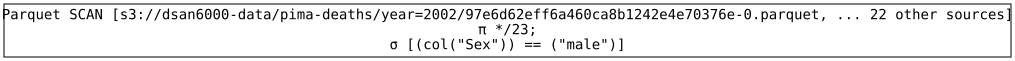

In [ ]:
filtered_lf = pima_lf.filter(is_male_expr)
print(type(filtered_lf))
filtered_lf.show_graph()

In [ ]:
filtered_pl = filtered_lf.collect()
print(type(filtered_pl))
filtered_pl

<class 'polars.dataframe.frame.DataFrame'>


ML Number,Name,Sex,Age,Reporting Date,Surface Management,Location,Location Precision,Corridor Code,Corridor,Cause of Death,OME Determined COD,Condition Code,Body Condition,Post Mortem Interval,State,County,Latitude,Longitude,UTM X,UTM Y,date_parsed,year
str,str,str,f64,str,str,str,str,i64,str,str,str,f64,str,str,str,str,f64,f64,i64,i64,datetime[μs],i64
"""02-00046""","""ARGUELLAS-HERRERA, CESAR LEOBA…","""male""",30.0,"""2002-01-06""","""Tohono Oodham Nation""","""HWY 86 MP 64/FED RT 34""","""vague physical description (pr…",8,"""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",32.206227,-112.571943,351848,3564378,2002-01-06 00:00:00,2002
"""02-00166""","""MOLINA PEREZ, TOMAS""","""male""",35.0,"""2002-01-27""","""Pima County Office of the Medi…","""SMH MORGUE""","""individual moved from location…",13,"""North of Corridor Divisions""","""Exposure""","""MULTISYSTEM ORGAN FAILURE COMP…",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Unknown""",32.175119,-110.928097,506780,3559848,2002-01-27 00:00:00,2002
"""02-00285""","""MARTINEZ-GRIJALVA, MARTIN""","""male""",38.0,"""2002-02-18""","""Bureau of Land Management""",null,"""physical description with dire…",7,"""San Miguel""","""Skeletal Remains""","""UNDETERMINED DUE TO SKELETAL R…",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""Pima""",32.40864,-111.5523,448066,3585865,2002-02-18 00:00:00,2002
"""02-00291""","""GRACIA-AGUIRRE, CARLOS""","""male""",25.0,"""2002-02-19""","""Tohono Oodham Nation""","""SR 86, MP 74""","""physical description with dire…",8,"""Cowlick""","""Blunt Force Injury""","""MULTIPLE BLUNT FORCE INJURIES""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",32.189906,-112.40556,367507,3562351,2002-02-19 00:00:00,2002
"""02-00304""","""SALAZAR-ONTIVEROS, CASTULO""","""male""",54.0,"""2002-02-21""","""Buenos Aires National Wildlife…","""3 MI E/O SR 286 MP 8 BUENOS AI…","""physical description with dire…",6,"""Sasabe""","""Heart Disease""","""MYOCARDITIS, PROBABLE VIRAL ET…",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""Pima""",31.57895,-111.46675,455713,3493861,2002-02-21 00:00:00,2002
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""24-4328""","""Perez Ramos, Gerson""","""male""",39.0,"""2024-12-15""","""US Forest Service""",null,"""GPS Coordinate (precise to wit…",5,"""Nogales""","""Exposure""","""Environmental cold exposure""",1.0,"""Fully fleshed""","""< 1 day""","""Arizona""","""SANTA CRUZ""",31.33377,-110.97839,502057,3466593,2024-12-15 00:00:00,2024
"""24-4349""","""Zarate Tobon, Osvaldo""","""male""",29.0,"""2024-12-17""","""Tohono Oodham Nation""",null,"""GPS Coordinate (precise to wit…",7,"""San Miguel""","""Skeletal Remains""","""Undetermined-skeletal remains""",6.0,"""Complete skeletonization w/ di…","""< 6-8 months ""","""Arizona""","""PIMA""",31.864712,-112.467332,361194,3526378,2024-12-17 00:00:00,2024
"""24-4454""","""Unidentified""","""male""",null,"""2024-12-25""","""Cabeza Prieta National Wildlif…",null,"""GPS Coordinate (precise to wit…",10,"""Cabeza Prieta""","""Skeletal Remains""","""Undetermined-skeletal remains""",7.0,"""Complete skeletonization w/ bo…","""> 6-8 months ""","""Arizona""","""PIMA""",32.2653,-113.10238,301975,3571782,2024-12-25 00:00:00,2024


### (5.3) Use Expression to *Group* Data

<class 'polars.lazyframe.frame.LazyFrame'>


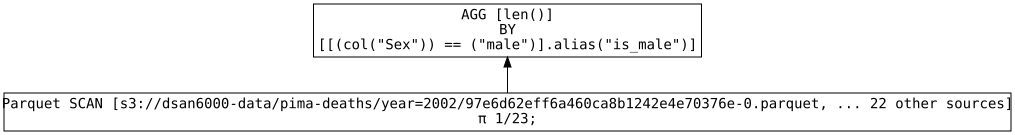

In [ ]:
count_lf = pima_lf.group_by(is_male_expr).len()
print(type(count_lf))
count_lf.show_graph()

In [ ]:
count_pl = count_lf.collect()
print(type(count_pl))
count_pl

<class 'polars.dataframe.frame.DataFrame'>


is_male,len
bool,u32
false,674
true,3361
null,3


## (6) Materializing Data *As Needed*

In [ ]:
ages_lf = pima_lf.select('Age')
print(type(ages_lf))

<class 'polars.lazyframe.frame.LazyFrame'>


In [ ]:
11 // 5

2

<class 'polars.lazyframe.frame.LazyFrame'>


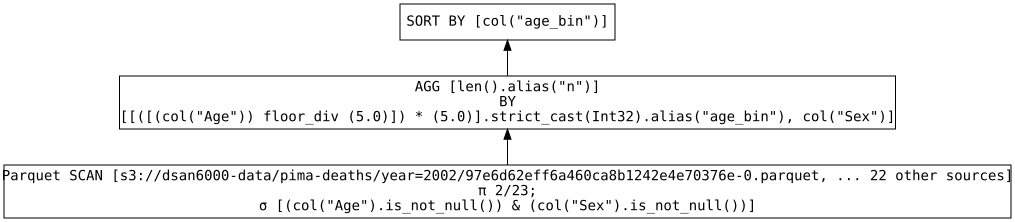

In [ ]:
counts_lf = (
    pima_lf.select(pl.col(['Age','Sex']))
      .filter(pl.col('Sex').is_not_null())
      .filter(pl.col('Age').is_not_null())
      .group_by([
          (pl.col('Age') // 5 * 5).cast(pl.Int32).alias('age_bin'),
          pl.col('Sex')
      ])
      .agg(pl.len().alias('n'))
      .sort('age_bin')
)
print(type(counts_lf))
counts_lf.show_graph()

In [ ]:
counts_pl = counts_lf.collect()
print(type(counts_pl))
counts_pl

<class 'polars.dataframe.frame.DataFrame'>


age_bin,Sex,n
i32,str,u32
0,"""male""",3
0,"""female""",3
5,"""female""",1
10,"""female""",7
10,"""male""",12
…,…,…
60,"""female""",1
60,"""male""",18
65,"""male""",3


In [ ]:
counts_pl.plot.bar(x="age_bin", y="n", color='Sex')

alt.Chart(...)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

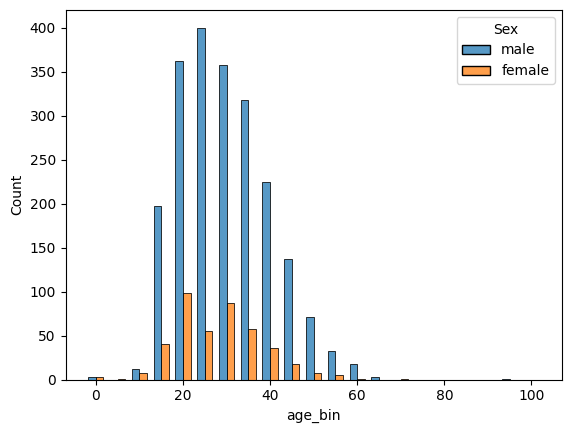

In [ ]:
sns.histplot(
    x='age_bin', weights='n', hue='Sex',
    data=counts_pl,
    binwidth=5, binrange=(0,100),
    discrete=True,
    multiple='dodge',
    shrink=3.5,
);
plt.show()